Original Dataset:
   Feature_1  Feature_2
0          1          1
1          2          2
2          2          3
3          3          2
4          8          8
5          9          9
6          9          8
7         10         10

GMM CLUSTERING RESULTS:
   Feature_1  Feature_2  Cluster
0          1          1        0
1          2          2        0
2          2          3        0
3          3          2        0
4          8          8        1
5          9          9        1
6          9          8        1
7         10         10        1

CLUSTER MEMBERSHIP PROBABILITIES:
   Cluster 0 Probability  Cluster 1 Probability
0                    1.0                    0.0
1                    1.0                    0.0
2                    1.0                    0.0
3                    1.0                    0.0
4                    0.0                    1.0
5                    0.0                    1.0
6                    0.0                    1.0
7                    0.0 

c:\Users\Ghanavi Arun\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Ghanavi Arun\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Ghanavi Arun\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Ghanavi Arun\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executabl

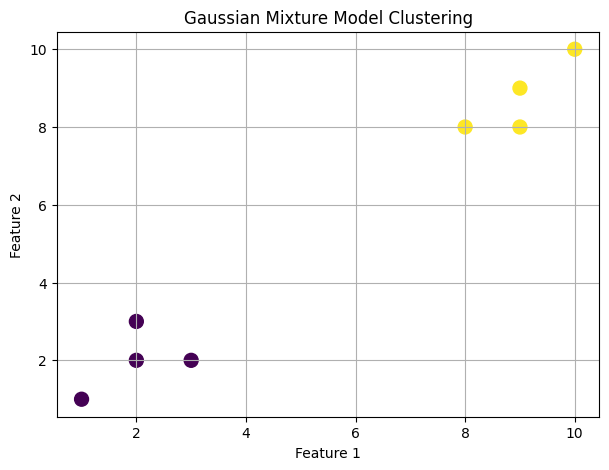

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.mixture import GaussianMixture


# -----------------------------------
# 1. CREATE A SMALL DATASET
# -----------------------------------

data = {
    "Feature_1": [1, 2, 2, 3, 8, 9, 9, 10],
    "Feature_2": [1, 2, 3, 2, 8, 9, 8, 10]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)


# -----------------------------------
# 2. APPLY GAUSSIAN MIXTURE MODEL
# -----------------------------------

X = df[["Feature_1", "Feature_2"]]

# Create GMM model with 2 clusters
gmm = GaussianMixture(
    n_components=2,
    random_state=42
)

# Train the model
gmm.fit(X)

# Predict cluster for each data point
df["Cluster"] = gmm.predict(X)

print("\nGMM CLUSTERING RESULTS:")
print(df)


# -----------------------------------
# 3. CLUSTER PROBABILITIES
# -----------------------------------

probabilities = gmm.predict_proba(X)

prob_df = pd.DataFrame(
    probabilities,
    columns=["Cluster 0 Probability", "Cluster 1 Probability"]
)

print("\nCLUSTER MEMBERSHIP PROBABILITIES:")
print(prob_df.round(3))


# -----------------------------------
# 4. DISPLAY CLUSTER MEANS
# -----------------------------------

print("\nCLUSTER MEANS:")
print(gmm.means_)


# -----------------------------------
# 5. VISUALIZE CLUSTERS
# -----------------------------------

plt.figure(figsize=(7, 5))

plt.scatter(
    X["Feature_1"],
    X["Feature_2"],
    c=df["Cluster"],
    s=100
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Gaussian Mixture Model Clustering")
plt.grid()

plt.show()